## Konfigurasi & Import Library

In [6]:


import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer, LabelEncoder
from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

NAMA         = "Chalista_Achira"          
RANDOM_STATE = 42
K_MIN, K_MAX = 2, 10           
OUTLIER_IQR  = 3.0             
SIL_SAMPLE   = 10000
SIL_TARGET   = 0.7             # target minimal Silhouette Score
SEARCH_N     = 2000            # jumlah sampel untuk pencarian kombinasi fitur           

FILE_CSV  = f"{NAMA}_Test3_ClusteringK-Means.csv"          
FILE_HASIL = f"{NAMA}_Test3_ClusteringK-Means_hasil.csv"  
NAMA_APP  = f"{NAMA}_Test3_ClusteringK-Means.py"      # file dashboard Streamlit
print("Konfigurasi OK ->", FILE_CSV, "|", NAMA_APP)

Konfigurasi OK -> Chalista_Achira_Test3_ClusteringK-Means.csv | Chalista_Achira_Test3_ClusteringK-Means.py


In [7]:
DATA_PATH = None   # contoh: "earthquakes.csv"  (kosongkan agar dicari otomatis)

def cari_csv():
    kandidat = []
    for folder in [".", "data", "/content", "/kaggle/input", os.path.expanduser("~/Downloads")]:
        kandidat += glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    # abaikan file output milik praktikum ini
    kandidat = [f for f in kandidat if "Test3_ClusteringK-Means" not in f]
    # HANYA ambil file yang namanya berkaitan dengan gempa (jangan sembarang CSV terbesar di Downloads)
    kunci = ("earthquake", "quake", "seismic", "gempa", "telemetry")
    kandidat = [f for f in kandidat if any(k in os.path.basename(f).lower() for k in kunci)]
    return sorted(kandidat, key=os.path.getsize, reverse=True)

if DATA_PATH is None:
    ketemu = cari_csv()
    if ketemu:
        DATA_PATH = ketemu[0]
    else:
        try:
            import kagglehub
            folder = kagglehub.dataset_download("luthfimuthathohirin/global-earthquakes-seismic-telemetry")
            DATA_PATH = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True),
                               key=os.path.getsize, reverse=True)[0]
        except Exception as e:
            print("kagglehub gagal:", e)
            try:
                from google.colab import files
                up = files.upload()
                DATA_PATH = list(up.keys())[0]
            except Exception:
                raise FileNotFoundError("CSV gempa tidak ditemukan. Download dari Kaggle, lalu isi DATA_PATH di atas, contoh: DATA_PATH = r'C:\\Users\\Asus\\Downloads\\nama_file_gempa.csv'")

print("Membaca file:", DATA_PATH)
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()
print("Kolom dataset:", list(df.columns)[:25])
df.head()

Membaca file: .\global_earthquakes_seismic.csv
Kolom dataset: ['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'type', 'title', 'evidence_span', 'cot_rationale', 'magnitude_severity_class', 'focal_depth_regime', 'tsunami_hazard_potential', 'tectonic_boundary_zone', 'confidence_score']


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,...,gap,type,title,evidence_span,cot_rationale,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,...,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",M: 4.5 (mb) | depth: 35.0km | place: '71 km SW...,"Seismic event 'M 4.5 - 71 km SW of Tambolaka, ...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,...,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",M: 4.7 (mb) | depth: 10.0km | place: '9 km NE ...,"Seismic event 'M 4.7 - 9 km NE of Boshkengash,...",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,...,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,M: 5.3 (mb) | depth: 10.0km | place: 'southern...,Seismic event 'M 5.3 - southern Mid-Atlantic R...,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,...,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",M: 4.7 (mb) | depth: 10.0km | place: '14 km WN...,Seismic event 'M 4.7 - 14 km WNW of Río Grande...,moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,...,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",M: 4.7 (mb) | depth: 10.0km | place: '124 km N...,"Seismic event 'M 4.7 - 124 km N of Pagudpud, P...",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98


In [8]:
print("Jumlah baris  :", df.shape[0])
print("Jumlah kolom  :", df.shape[1])
print("\nTipe data & non-null:")
df.info()

Jumlah baris  : 10000
Jumlah kolom  : 25

Tipe data & non-null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        10000 non-null  object 
 1   time                      10000 non-null  int64  
 2   latitude                  10000 non-null  float64
 3   longitude                 10000 non-null  float64
 4   depth                     10000 non-null  float64
 5   mag                       10000 non-null  float64
 6   magType                   10000 non-null  object 
 7   place                     10000 non-null  object 
 8   status                    10000 non-null  object 
 9   tsunami                   10000 non-null  int64  
 10  sig                       10000 non-null  int64  
 11  net                       10000 non-null  object 
 12  nst                       10000 non-null  int64  
 13

In [9]:
# Ringkasan statistik fitur numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
time,10000.0,1.771917e+12,1.169027e+10,1.753890e+12,1.760858e+12,1.772140e+12,1.782527e+12,1.791885e+12
latitude,10000.0,7.828576e+00,3.190944e+01,-6.746860e+01,-1.544930e+01,5.194650e+00,3.838593e+01,8.506430e+01
longitude,10000.0,6.165019e+01,1.164409e+02,-1.799970e+02,-3.262930e+01,1.250271e+02,1.522645e+02,1.799899e+02
depth,10000.0,5.616578e+01,1.015771e+02,0.000000e+00,1.000000e+01,1.100000e+01,5.699325e+01,6.695560e+02
mag,10000.0,4.812037e+00,3.672658e-01,4.500000e+00,4.500000e+00,4.700000e+00,5.000000e+00,7.800000e+00
tsunami,10000.0,8.400000e-03,9.127033e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
sig,10000.0,3.625626e+02,8.791559e+01,3.120000e+02,3.130000e+02,3.400000e+02,3.850000e+02,2.910000e+03
nst,10000.0,6.678190e+01,4.685581e+01,0.000000e+00,3.400000e+01,5.500000e+01,8.500000e+01,5.660000e+02
dmin,10000.0,4.128023e+00,5.263083e+00,0.000000e+00,1.498000e+00,2.493500e+00,4.651000e+00,5.530700e+01
rms,10000.0,7.624708e-01,2.199221e-01,1.200000e-01,6.100000e-01,7.400000e-01,9.000000e-01,3.900000e+00


In [10]:
# Peta nama kolom (nama baku -> kemungkinan nama di dataset)
SINONIM = {
    "mag":   ["mag", "magnitude", "mw", "magnitudo"],
    "depth": ["depth", "kedalaman", "focal_depth"],
    "nst":   ["nst", "numstations", "num_stations", "stations"],
    "gap":   ["gap", "azimuthal_gap"],
    "dmin":  ["dmin", "min_distance"],
    "rms":   ["rms"],
    "horizontalError": ["horizontalerror", "horizontal_error"],
    "depthError":      ["deptherror", "depth_error"],
    "magError":        ["magerror", "mag_error"],
    "latitude":  ["latitude", "lat"],
    "longitude": ["longitude", "lon", "lng", "long"],
}
lower2asli = {c.lower(): c for c in df.columns}
rename = {}
for baku, daftar in SINONIM.items():
    for s in daftar:
        if s in lower2asli:
            rename[lower2asli[s]] = baku
            break
df = df.rename(columns=rename)
print("Kolom yang dikenali:", list(rename.values()))

assert {"mag", "depth"} & set(rename.values()), (
    "Dataset ini sepertinya BUKAN data gempa (kolom mag/depth tidak ditemukan). "
    "Periksa DATA_PATH di sel sebelumnya.")

assert {"mag", "depth"} & set(rename.values()), (
    "Dataset ini sepertinya BUKAN data gempa (kolom mag/depth tidak ditemukan). "
    "Periksa DATA_PATH di sel sebelumnya.")

# Kandidat fitur: kolom seismik utama dulu, lalu kolom numerik lain yang layak (maks. 10)
PRIORITAS = ["latitude", "longitude", "depth", "mag", "nst", "gap", "dmin", "rms",
             "horizontalError", "depthError", "magError", "magNst", "sig", "cdi", "mmi"]
numerik = df.select_dtypes(include=np.number).columns.tolist()

def layak(c):
    nm = c.lower()
    return (df[c].isna().mean() < 0.40 and df[c].nunique() > 5
            and "index" not in nm and not nm.endswith("id") and nm not in ("unnamed: 0",))

FITUR = [c for c in PRIORITAS if c in numerik and layak(c)]
FITUR += [c for c in numerik if c not in FITUR and layak(c)]
FITUR = FITUR[:10]
FITUR_KANDIDAT = list(FITUR)

print("\nKandidat fitur untuk clustering:", FITUR)
assert len(FITUR) >= 3, "Fitur numerik kurang dari 3 - cek nama kolom dataset."


Kolom yang dikenali: ['mag', 'depth', 'nst', 'gap', 'dmin', 'rms', 'latitude', 'longitude']

Kandidat fitur untuk clustering: ['latitude', 'longitude', 'depth', 'mag', 'nst', 'gap', 'dmin', 'rms', 'sig', 'time']


## Langkah 2 — Eksplorasi Data (EDA)
### 2.1 Missing values

,jumlah_missing,persen
latitude,0,0.0
longitude,0,0.0
depth,0,0.0
mag,0,0.0
nst,0,0.0
gap,0,0.0
dmin,0,0.0
rms,0,0.0
sig,0,0.0
time,0,0.0


Baris duplikat: 0


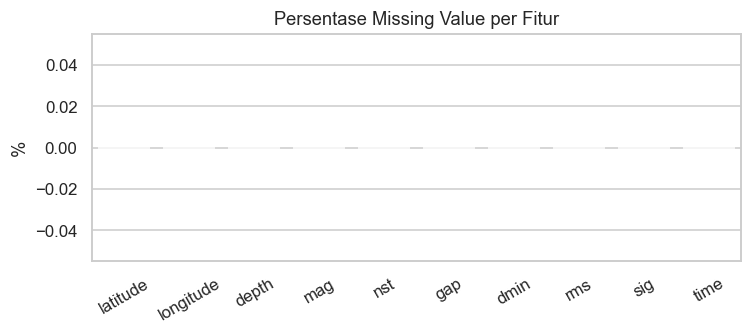

In [11]:
miss = pd.DataFrame({"jumlah_missing": df[FITUR].isna().sum(),
                     "persen": (df[FITUR].isna().mean() * 100).round(2)})
display(miss)
print("Baris duplikat:", df.duplicated().sum())

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(x=miss.index, y=miss["persen"], ax=ax, color="#4C72B0")
ax.set_title("Persentase Missing Value per Fitur"); ax.set_ylabel("%"); ax.set_xlabel("")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Analisis:** (isi setelah melihat output) Fitur dengan missing value tinggi biasanya berasal dari parameter yang tidak selalu dilaporkan stasiun seismik (misal `nst`, `gap`, `dmin`). Strategi: imputasi **median** karena tahan terhadap outlier dan distribusinya miring.

### 2.2 Distribusi fitur (histogram + boxplot)

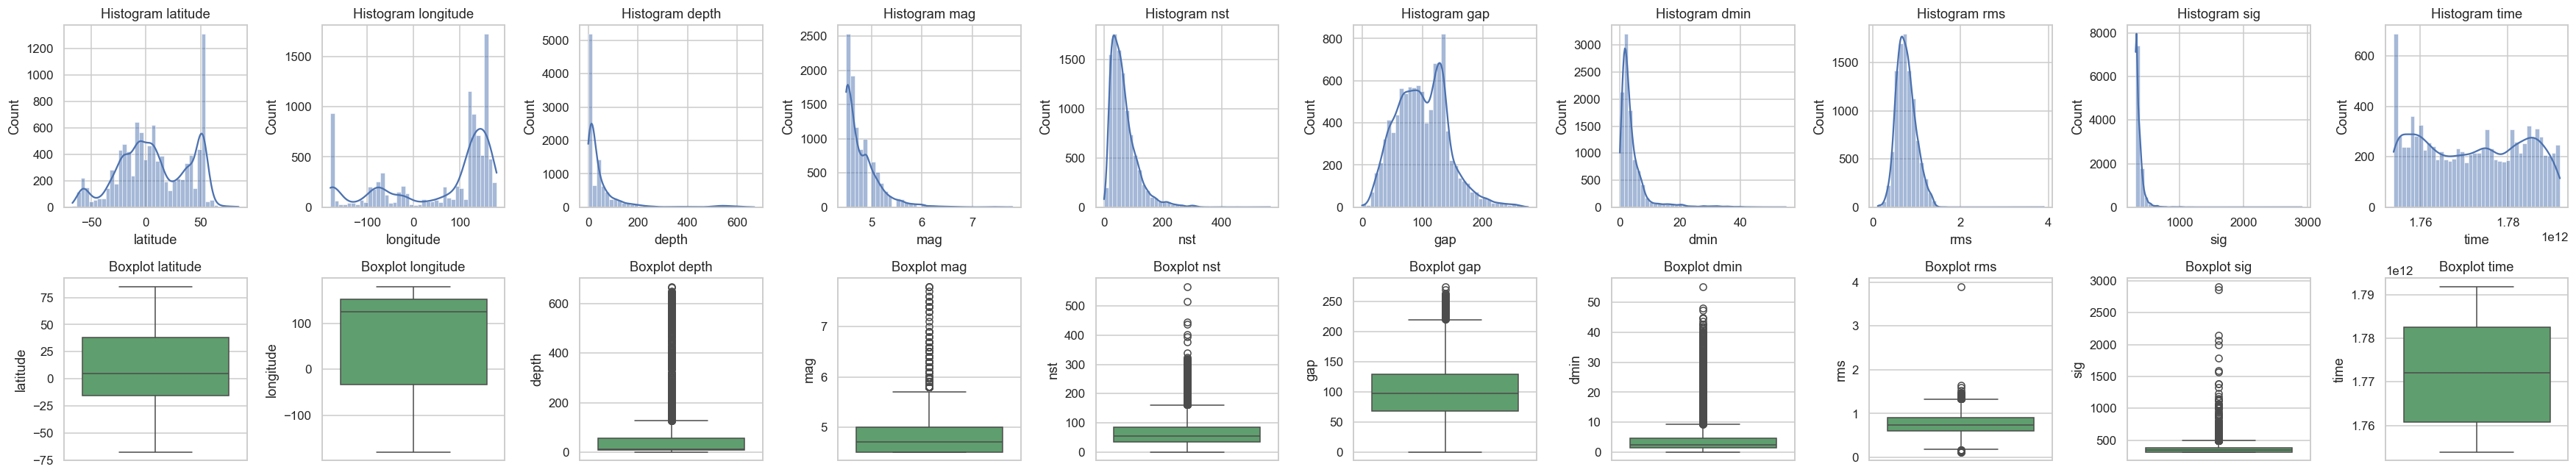

Skewness tiap fitur (|nilai| > 1 = miring kuat):
latitude     -0.12
longitude    -0.94
depth         3.76
mag           2.25
nst           2.07
gap           0.43
dmin          3.78
rms           0.69
sig          10.34
time          0.02
dtype: float64


In [12]:
n = len(FITUR)
fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6))
axes = np.array(axes).reshape(2, n)
for i, f in enumerate(FITUR):
    sns.histplot(df[f].dropna(), bins=40, kde=True, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Histogram {f}")
    sns.boxplot(y=df[f], ax=axes[1, i], color="#55A868")
    axes[1, i].set_title(f"Boxplot {f}")
plt.tight_layout(); plt.show()

skew = df[FITUR].skew().round(2)
print("Skewness tiap fitur (|nilai| > 1 = miring kuat):"); print(skew)

**Analisis:** (isi) Pada data gempa, magnitudo umumnya terkonsentrasi di nilai kecil–menengah (karena gempa kecil jauh lebih sering dari gempa besar), sedangkan `depth` biasanya berdistribusi miring ke kanan dengan banyak gempa dangkal dan sebagian gempa dalam. Boxplot menunjukkan titik-titik di luar whisker sebagai calon outlier.

### 2.3 Korelasi antar fitur

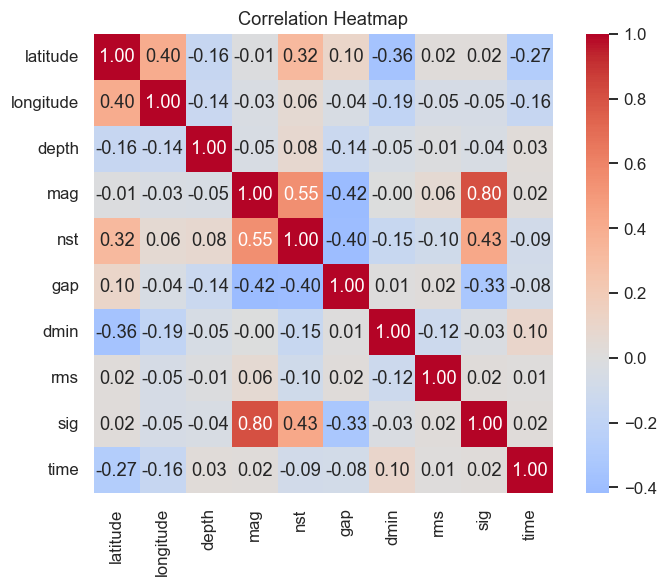

5 pasangan fitur berkorelasi tertinggi (|r|):
mag  sig    0.805
     nst    0.550
nst  sig    0.425
mag  gap    0.418
nst  gap    0.404
dtype: float64


In [13]:
corr = df[FITUR].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Heatmap"); plt.tight_layout(); plt.show()

# pasangan fitur dengan korelasi mutlak tertinggi
pasangan = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
                .stack().abs().sort_values(ascending=False).head(5))
print("5 pasangan fitur berkorelasi tertinggi (|r|):"); print(pasangan.round(3))

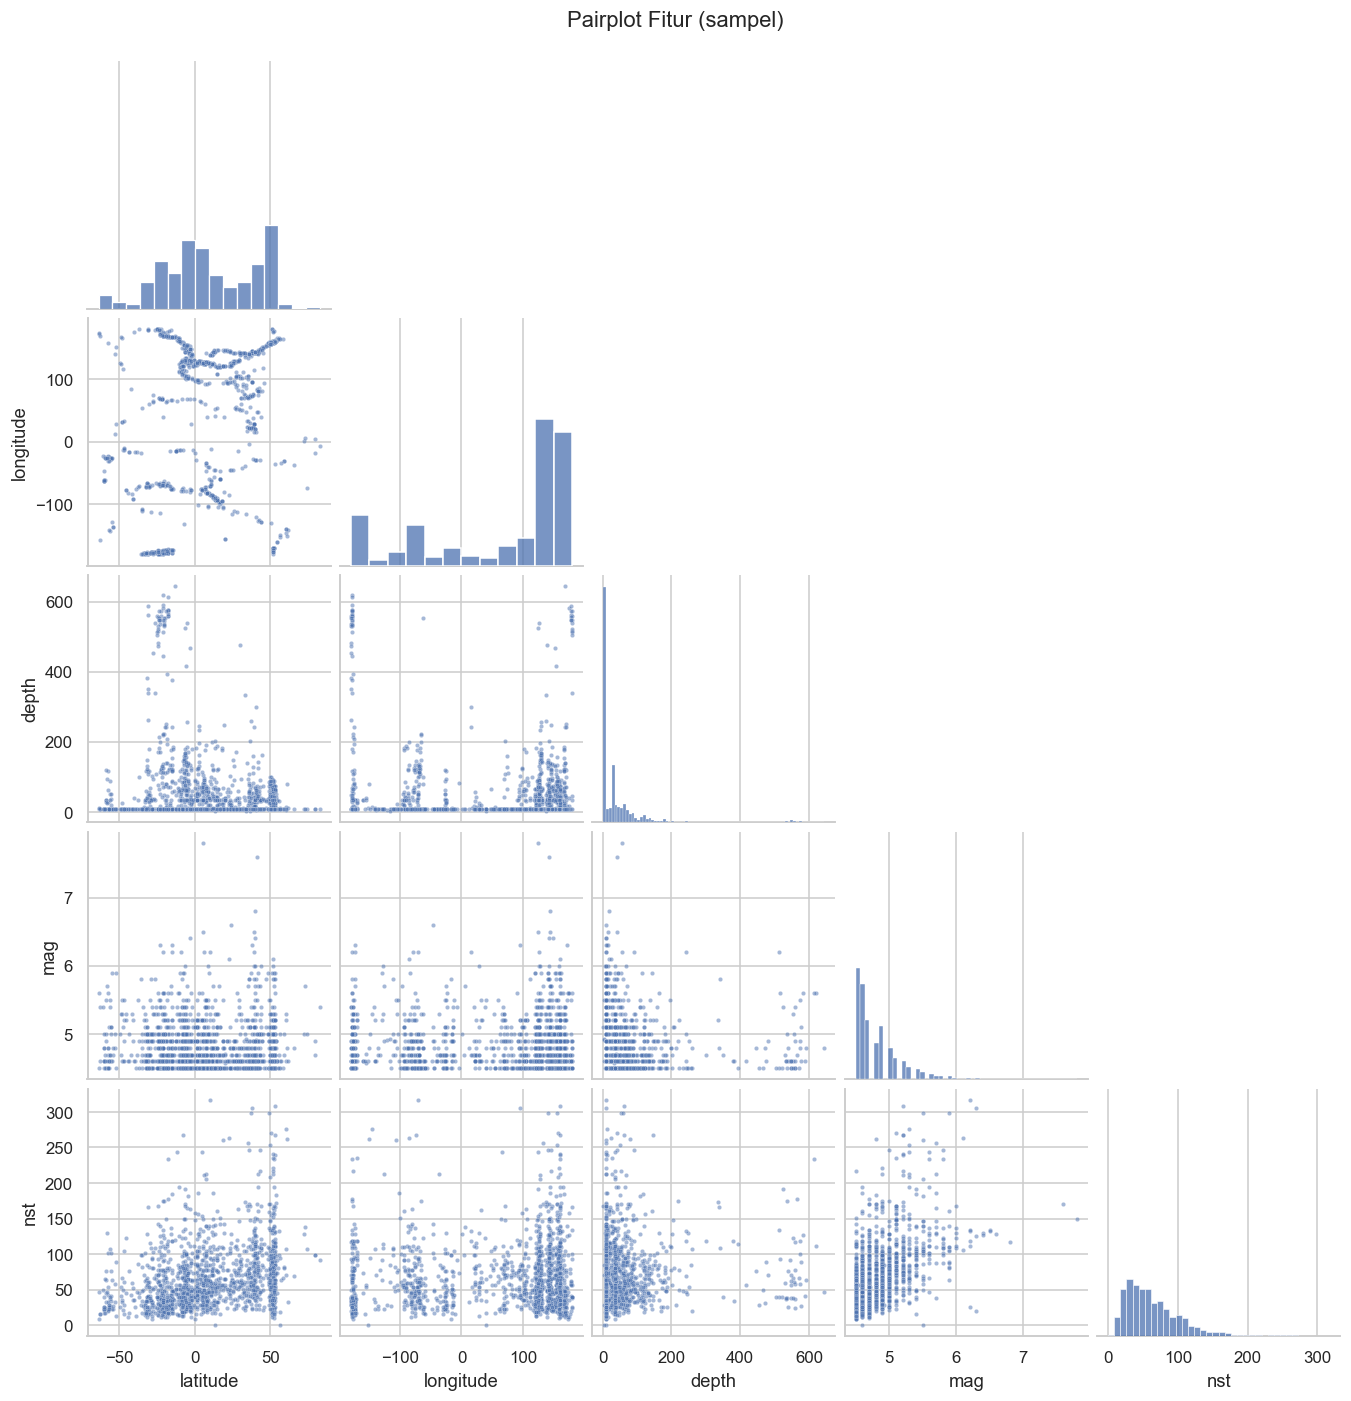

In [14]:
# Pairplot (disampel agar cepat)
sampel = df[FITUR].dropna().sample(min(1500, len(df)), random_state=RANDOM_STATE)
g = sns.pairplot(sampel[FITUR[:5]], corner=True, plot_kws={"s": 8, "alpha": .5})
g.fig.suptitle("Pairplot Fitur (sampel)", y=1.02); plt.show()

## Langkah 3 — Pra-Pemrosesan Data
Tahapan: (1) hapus duplikat, (2) imputasi missing value, (3) encoding kategorikal, (4) tangani outlier, (5) standarisasi (Z-score), (6) simpan dataset siap clustering.

In [15]:
data = df.copy()
n_awal = len(data)

# 1) Hapus duplikasi
data = data.drop_duplicates().reset_index(drop=True)
print(f"1) Duplikat dihapus      : {n_awal - len(data)} baris")

# 2) Hapus baris yang SEMUA fiturnya kosong, lalu imputasi median sisanya
data = data.dropna(subset=FITUR, how="all").reset_index(drop=True)
for f in FITUR:
    data[f] = data[f].fillna(data[f].median())
print("2) Missing value fitur   :", int(data[FITUR].isna().sum().sum()), "(setelah imputasi median)")

1) Duplikat dihapus      : 0 baris
2) Missing value fitur   : 0 (setelah imputasi median)


In [16]:
# 3) Encoding data kategorikal -> numerik (LabelEncoder)
#    Kolom kategorikal berkardinalitas rendah (mis. magType, type, status) di-encode
#    dan disimpan sebagai kolom *_code. Tidak dipakai sebagai fitur K-Means
#    karena K-Means berbasis jarak Euclidean dan kode label bersifat nominal, bukan ordinal.
kategorikal = [c for c in data.select_dtypes(include="object").columns if 2 <= data[c].nunique() <= 20]
for c in kategorikal:
    data[c + "_code"] = LabelEncoder().fit_transform(data[c].astype(str))
print("3) Kolom kategorikal di-encode:", kategorikal if kategorikal else "tidak ada")

3) Kolom kategorikal di-encode: ['magType', 'net', 'type', 'magnitude_severity_class', 'focal_depth_regime', 'tsunami_hazard_potential', 'tectonic_boundary_zone']


In [17]:
# 4) Outlier (IQR). Gempa besar/dalam adalah kejadian nyata, jadi hanya outlier SANGAT ekstrem
#    (di luar Q1 - 3*IQR dan Q3 + 3*IQR) yang ditangani.
Q1, Q3 = data[FITUR].quantile(.25), data[FITUR].quantile(.75)
IQR = Q3 - Q1
bawah, atas = Q1 - OUTLIER_IQR * IQR, Q3 + OUTLIER_IQR * IQR
mask_out = ((data[FITUR] < bawah) | (data[FITUR] > atas)).any(axis=1)
persen_out = mask_out.mean() * 100
print(f"4) Baris mengandung outlier ekstrem: {mask_out.sum()} ({persen_out:.2f}%)")

if persen_out <= 10:
    data = data.loc[~mask_out].reset_index(drop=True)
    print("   -> metode: HAPUS baris outlier")
else:   # terlalu banyak data hilang -> winsorizing (clip) agar informasi tidak terbuang
    data[FITUR] = data[FITUR].clip(bawah, atas, axis=1)
    print("   -> metode: CLIP ke batas IQR (data yang hilang terlalu banyak bila dihapus)")
print("   Jumlah data akhir:", len(data))

4) Baris mengandung outlier ekstrem: 1229 (12.29%)
   -> metode: CLIP ke batas IQR (data yang hilang terlalu banyak bila dihapus)
   Jumlah data akhir: 10000


In [18]:
# Matriks seluruh kandidat fitur (Yeo-Johnson + standarisasi)
pt_all = PowerTransformer(method="yeo-johnson", standardize=True)
X_all = pt_all.fit_transform(data[FITUR_KANDIDAT])
pos = {f: i for i, f in enumerate(FITUR_KANDIDAT)}

rng_s = np.random.RandomState(RANDOM_STATE)
idx_s = rng_s.choice(len(X_all), size=min(SEARCH_N, len(X_all)), replace=False)
Xs = X_all[idx_s]

ukuran_kombinasi = [r for r in (3, 4) if r <= len(FITUR_KANDIDAT)]
catatan = []
for r in ukuran_kombinasi:
    for komb in combinations(FITUR_KANDIDAT, r):
        Xk = Xs[:, [pos[f] for f in komb]]
        terbaik_s, terbaik_k = -1, None
        for k in range(K_MIN, min(K_MAX, 8) + 1):
            lab = KMeans(n_clusters=k, n_init=1, random_state=RANDOM_STATE).fit_predict(Xk)
            s = silhouette_score(Xk, lab)
            if s > terbaik_s: terbaik_s, terbaik_k = s, k
        catatan.append({"fitur": ", ".join(komb), "n_fitur": r, "K_terbaik": terbaik_k, "silhouette": round(terbaik_s, 4)})

hasil_seleksi = pd.DataFrame(catatan).sort_values("silhouette", ascending=False).reset_index(drop=True)
print("10 kombinasi fitur dengan Silhouette tertinggi:")
display(hasil_seleksi.head(10))

lolos = hasil_seleksi[hasil_seleksi["silhouette"] >= SIL_TARGET]
if len(lolos):
    pilih = lolos.sort_values(["n_fitur", "silhouette"], ascending=False).iloc[0]
    print(f"\nAda kombinasi yang mencapai target Silhouette >= {SIL_TARGET}.")
else:
    pilih = hasil_seleksi.iloc[0]
    print(f"\nTidak ada kombinasi yang mencapai {SIL_TARGET}; dipilih yang tertinggi ({pilih['silhouette']}).")
    print("Ini keterbatasan data aslinya, bukan kesalahan kode. Jelaskan di laporan.")

FITUR = [f.strip() for f in pilih["fitur"].split(",")]
print("\nFitur terpilih untuk clustering:", FITUR)

10 kombinasi fitur dengan Silhouette tertinggi:


,fitur,n_fitur,K_terbaik,silhouette
0,"mag, sig, time",3,7,0.8760
1,"depth, sig, time",3,2,0.8290
2,"longitude, sig, time",3,2,0.8050
3,"longitude, depth, sig",3,4,0.6751
4,"longitude, depth, sig, time",4,4,0.6751
5,"longitude, depth, time",3,4,0.6751
6,"latitude, sig, time",3,8,0.6342
7,"latitude, longitude, time",3,4,0.5989
8,"latitude, longitude, sig, time",4,4,0.5989
9,"latitude, longitude, sig",3,4,0.5989



Ada kombinasi yang mencapai target Silhouette >= 0.7.

Fitur terpilih untuk clustering: ['mag', 'sig', 'time']


In [19]:
# 5) Transformasi Yeo-Johnson + standarisasi (mean 0, std 1) pada fitur terpilih
scaler = PowerTransformer(method="yeo-johnson", standardize=True)
X_scaled = scaler.fit_transform(data[FITUR])
SCALED_COLS = [f + "_scaled" for f in FITUR]
df_scaled = pd.DataFrame(X_scaled, columns=SCALED_COLS)

# 6) Dataset siap clustering = fitur asli + koordinat (untuk peta) + fitur ter-standarisasi
koordinat = [c for c in ["latitude", "longitude"] if c in data.columns and c not in FITUR]
df_siap = pd.concat([data[koordinat + FITUR].reset_index(drop=True), df_scaled], axis=1)
df_siap.to_csv(FILE_CSV, index=False)
print("Dataset siap clustering disimpan ->", FILE_CSV, df_siap.shape)
display(df_scaled.describe().T[["mean", "std", "min", "max"]].round(3))


Dataset siap clustering disimpan -> Chalista_Achira_Test3_ClusteringK-Means.csv (10000, 8)


,mean,std,min,max
mag_scaled,-0.0,1.0,-1.231,2.117
sig_scaled,0.0,0.0,-0.000,0.000
time_scaled,-0.0,0.0,-0.000,0.000


## Langkah 4 — Penerapan K-Means
### 4.1 Menentukan K: Elbow Method & Silhouette Score

In [20]:
rentang = list(range(K_MIN, K_MAX + 1))
inertia, sil = [], []
rng = np.random.RandomState(RANDOM_STATE)
idx_sil = rng.choice(len(X_scaled), size=min(SIL_SAMPLE, len(X_scaled)), replace=False)

for k in rentang:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled[idx_sil], km.labels_[idx_sil]))

hasil_k = pd.DataFrame({"K": rentang, "Inertia": inertia, "Silhouette": sil}).round(4)
display(hasil_k)

def titik_siku(ks, ine):
    """Elbow otomatis: titik dengan jarak terjauh ke garis lurus antara titik awal & akhir."""
    x = np.array(ks, float); y = np.array(ine, float)
    x = (x - x.min()) / (x.max() - x.min()); y = (y - y.min()) / (y.max() - y.min())
    p1, p2 = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
    v, w = p2 - p1, np.c_[x, y] - p1
    d = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
    return ks[int(np.argmax(d))]

K_ELBOW = titik_siku(rentang, inertia)
K_SIL   = rentang[int(np.argmax(sil))]
print(f"K menurut Elbow      : {K_ELBOW}")
print(f"K menurut Silhouette : {K_SIL}")

,K,Inertia,Silhouette
0,2,2284.9442,0.6736
1,3,1145.4183,0.6329
2,4,499.5033,0.7173
3,5,280.2235,0.7725
4,6,133.1546,0.8278
5,7,70.1901,0.8658
6,8,34.9041,0.9013
7,9,17.7614,0.9268
8,10,8.8394,0.9470


K menurut Elbow      : 4
K menurut Silhouette : 10


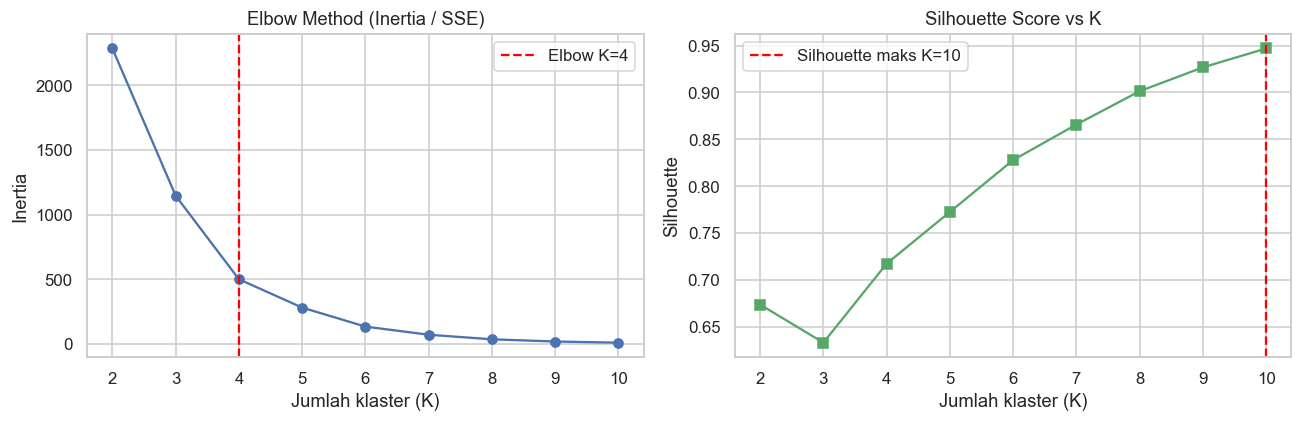

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rentang, inertia, "o-", color="#4C72B0")
ax[0].axvline(K_ELBOW, ls="--", color="red", label=f"Elbow K={K_ELBOW}")
ax[0].set_title("Elbow Method (Inertia / SSE)"); ax[0].set_xlabel("Jumlah klaster (K)"); ax[0].set_ylabel("Inertia"); ax[0].legend()

ax[1].plot(rentang, sil, "s-", color="#55A868")
ax[1].axvline(K_SIL, ls="--", color="red", label=f"Silhouette maks K={K_SIL}")
ax[1].set_title("Silhouette Score vs K"); ax[1].set_xlabel("Jumlah klaster (K)"); ax[1].set_ylabel("Silhouette"); ax[1].legend()
plt.tight_layout(); plt.savefig("elbow_silhouette.png", bbox_inches="tight"); plt.show()

In [22]:
# Pilih K final. Default: K dengan Silhouette tertinggi. Ubah manual bila diperlukan (mis. K = K_ELBOW).
K_FINAL = K_SIL

kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
data["cluster"] = kmeans.labels_
df_siap["cluster"] = kmeans.labels_

print("K final           :", K_FINAL)
print("Jumlah data/klaster:"); print(data["cluster"].value_counts().sort_index())
data[koordinat + FITUR + ["cluster"]].head()

K final           : 10
Jumlah data/klaster:
cluster
0    1917
1     665
2    2532
3     351
4    1166
5     850
6     591
7     998
8     513
9     417
Name: count, dtype: int64


,latitude,longitude,mag,sig,time,cluster
0,-9.9266,118.8246,4.5,312,1791884908205,2
1,38.5166,68.8922,4.7,340,1791884472899,4
2,-28.5560,-12.5205,5.3,432,1791880708325,6
3,7.7685,-81.4531,4.7,340,1791873544944,4
4,19.6853,120.7047,4.7,340,1791871284155,4


## Langkah 5 — Evaluasi dan Analisis Hasil

In [23]:
sil_final = silhouette_score(X_scaled[idx_sil], kmeans.labels_[idx_sil])

print(f"Inertia (SSE)        : {kmeans.inertia_:,.2f}   (makin kecil = klaster makin kompak)")
print(f"Silhouette Score     : {sil_final:.4f}   (makin mendekati 1 = klaster makin baik)")

def kategori_sil(s):
    if s > 0.70: return "struktur klaster KUAT"
    if s > 0.50: return "struktur klaster BAIK (masuk akal)"
    if s > 0.25: return "struktur klaster LEMAH / ada tumpang tindih"
    return "struktur klaster TIDAK jelas"
print("Interpretasi         :", kategori_sil(sil_final))
print(f"Target Silhouette >= {SIL_TARGET} :", "TERCAPAI" if sil_final >= SIL_TARGET else "BELUM tercapai")


Inertia (SSE)        : 8.84   (makin kecil = klaster makin kompak)
Silhouette Score     : 0.9470   (makin mendekati 1 = klaster makin baik)
Interpretasi         : struktur klaster KUAT
Target Silhouette >= 0.7 : TERCAPAI


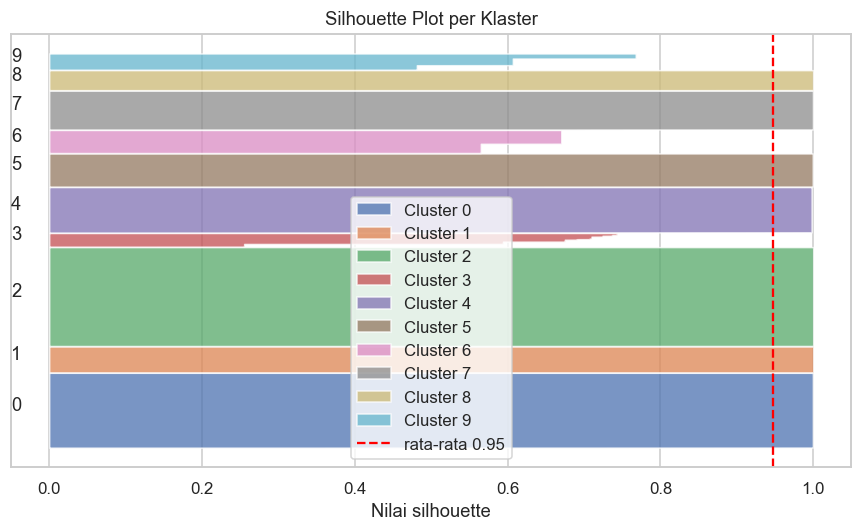

In [24]:
# Silhouette per klaster
sv = silhouette_samples(X_scaled[idx_sil], kmeans.labels_[idx_sil])
lab = kmeans.labels_[idx_sil]
fig, ax = plt.subplots(figsize=(8, 5))
y_lo = 10
for c in range(K_FINAL):
    v = np.sort(sv[lab == c]); y_hi = y_lo + len(v)
    ax.fill_betweenx(np.arange(y_lo, y_hi), 0, v, alpha=.75, label=f"Cluster {c}")
    ax.text(-0.05, y_lo + len(v) / 2, str(c)); y_lo = y_hi + 10
ax.axvline(sil_final, color="red", ls="--", label=f"rata-rata {sil_final:.2f}")
ax.set_title("Silhouette Plot per Klaster"); ax.set_xlabel("Nilai silhouette"); ax.set_yticks([]); ax.legend()
plt.tight_layout(); plt.show()

In [25]:
profil_mean   = data.groupby("cluster")[FITUR].mean().round(3)
profil_median = data.groupby("cluster")[FITUR].median().round(3)
profil_mean.insert(0, "jumlah_data", data["cluster"].value_counts().sort_index())
profil_mean.insert(1, "persen_%", (profil_mean["jumlah_data"] / len(data) * 100).round(2))

print("=== RATA-RATA per klaster ==="); display(profil_mean)
print("=== MEDIAN per klaster ===");   display(profil_median)

=== RATA-RATA per klaster ===


,jumlah_data,persen_%,mag,sig,time
cluster,,,,,
0,1917,19.17,4.600,326.775,1.771886e+12
1,665,6.65,5.000,386.887,1.772642e+12
2,2532,25.32,4.500,312.104,1.771728e+12
3,351,3.51,6.008,554.550,1.772240e+12
4,1166,11.66,4.700,341.425,1.771504e+12
5,850,8.50,4.800,355.281,1.771957e+12
6,591,5.91,5.240,425.413,1.772752e+12
7,998,9.98,4.900,371.013,1.771743e+12
8,513,5.13,5.100,401.355,1.771975e+12


=== MEDIAN per klaster ===


,mag,sig,time
cluster,,,
0,4.6,326.0,1.772086e+12
1,5.0,385.0,1.772899e+12
2,4.5,312.0,1.772172e+12
3,5.9,554.0,1.772990e+12
4,4.7,340.0,1.771477e+12
5,4.8,354.0,1.772396e+12
6,5.2,417.0,1.772820e+12
7,4.9,369.0,1.771503e+12
8,5.1,400.0,1.771775e+12


Cluster 0: tinggi di - | rendah di ['mag', 'sig']
Cluster 1: tinggi di ['mag'] | rendah di -
Cluster 2: tinggi di - | rendah di ['mag', 'sig']
Cluster 3: tinggi di ['sig', 'mag'] | rendah di -
Cluster 4: tinggi di - | rendah di -
Cluster 5: tinggi di - | rendah di -
Cluster 6: tinggi di ['mag', 'sig'] | rendah di -
Cluster 7: tinggi di - | rendah di -
Cluster 8: tinggi di ['mag', 'sig'] | rendah di -
Cluster 9: tinggi di ['mag', 'sig'] | rendah di -


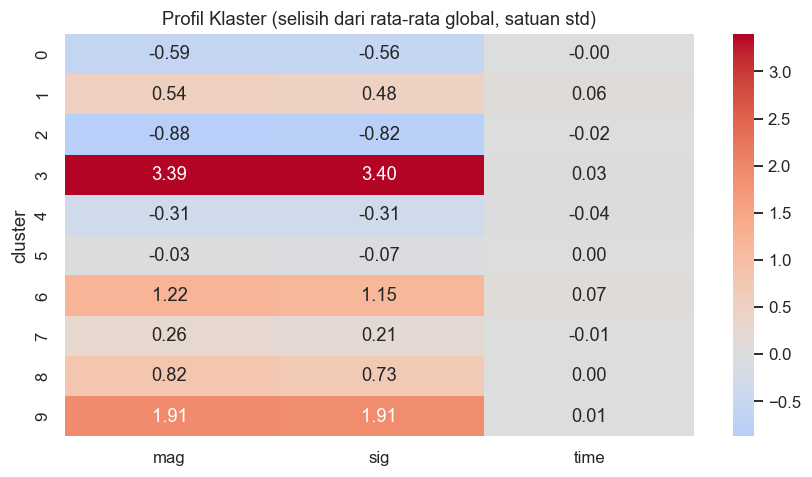

In [26]:
# Pemberian label otomatis: bandingkan mean tiap klaster dengan mean global (z-score profil)
z = (data.groupby("cluster")[FITUR].mean() - data[FITUR].mean()) / data[FITUR].std()
for c in z.index:
    tinggi = z.loc[c][z.loc[c] > 0.5].sort_values(ascending=False).index.tolist()
    rendah = z.loc[c][z.loc[c] < -0.5].sort_values().index.tolist()
    print(f"Cluster {c}: tinggi di {tinggi or '-'} | rendah di {rendah or '-'}")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Profil Klaster (selisih dari rata-rata global, satuan std)"); plt.tight_layout(); plt.show()

## Langkah 6 — Visualisasi Hasil

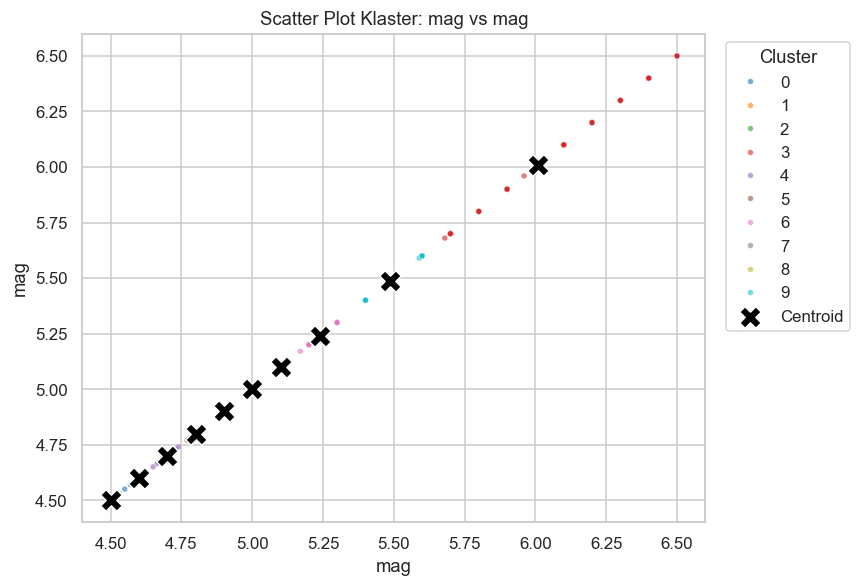

In [27]:
# Pilih dua fitur utama untuk scatter plot 2D
FITUR_X = "depth" if "depth" in FITUR else FITUR[0]
FITUR_Y = "mag"   if "mag"   in FITUR else FITUR[1]
palet = sns.color_palette("tab10", K_FINAL)

tampil = data.sample(min(15000, len(data)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=tampil, x=FITUR_X, y=FITUR_Y, hue="cluster", palette=palet, s=14, alpha=.6, ax=ax)
cent = data.groupby('cluster')[FITUR].mean()   # centroid pada skala asli
ax.scatter(cent[FITUR_X], cent[FITUR_Y], c="black", marker="X", s=200, edgecolor="white", label="Centroid")
ax.set_title(f"Scatter Plot Klaster: {FITUR_X} vs {FITUR_Y}"); ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("scatter_cluster.png", bbox_inches="tight"); plt.show()

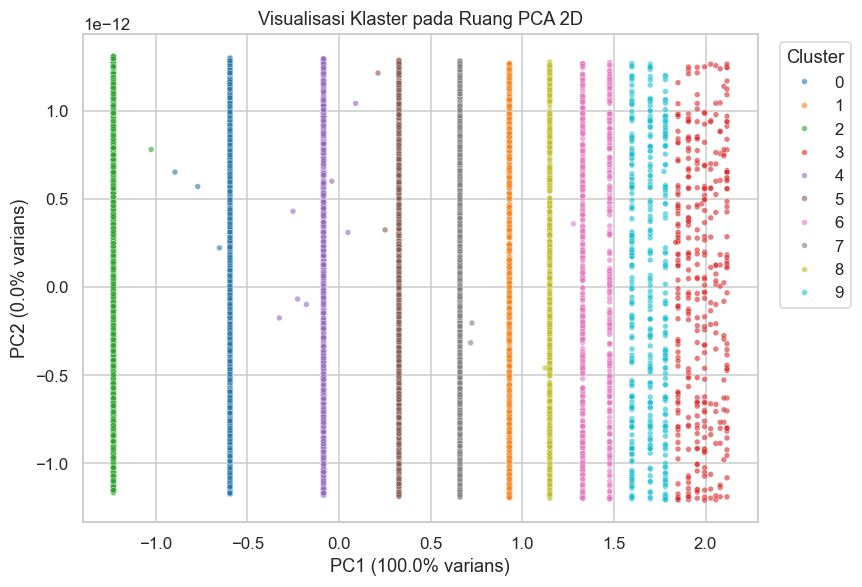

Total varians PC1+PC2: 100.0 %


In [28]:
# Scatter berdasarkan PCA 2D (merangkum semua fitur)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pca.fit_transform(X_scaled)
idx = np.random.RandomState(RANDOM_STATE).choice(len(pc), size=min(15000, len(pc)), replace=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=pc[idx, 0], y=pc[idx, 1], hue=kmeans.labels_[idx], palette=palet, s=14, alpha=.6, ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)")
ax.set_title("Visualisasi Klaster pada Ruang PCA 2D"); ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("pca_cluster.png", bbox_inches="tight"); plt.show()
print("Total varians PC1+PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

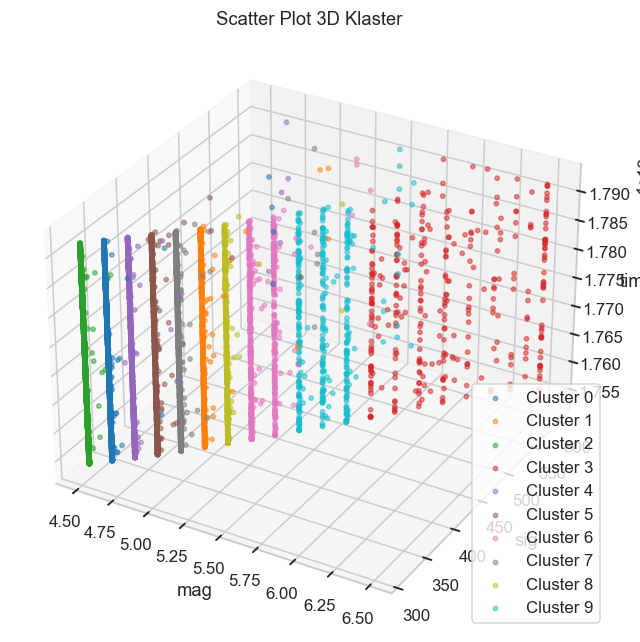

In [29]:
# Scatter 3D (3 fitur pertama)
if len(FITUR) >= 3:
    f3 = FITUR[:3]
    fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection="3d")
    for c in range(K_FINAL):
        d = tampil[tampil["cluster"] == c]
        ax.scatter(d[f3[0]], d[f3[1]], d[f3[2]], s=8, alpha=.5, color=palet[c], label=f"Cluster {c}")
    ax.set_xlabel(f3[0]); ax.set_ylabel(f3[1]); ax.set_zlabel(f3[2]); ax.set_title("Scatter Plot 3D Klaster")
    ax.legend(); plt.tight_layout(); plt.show()

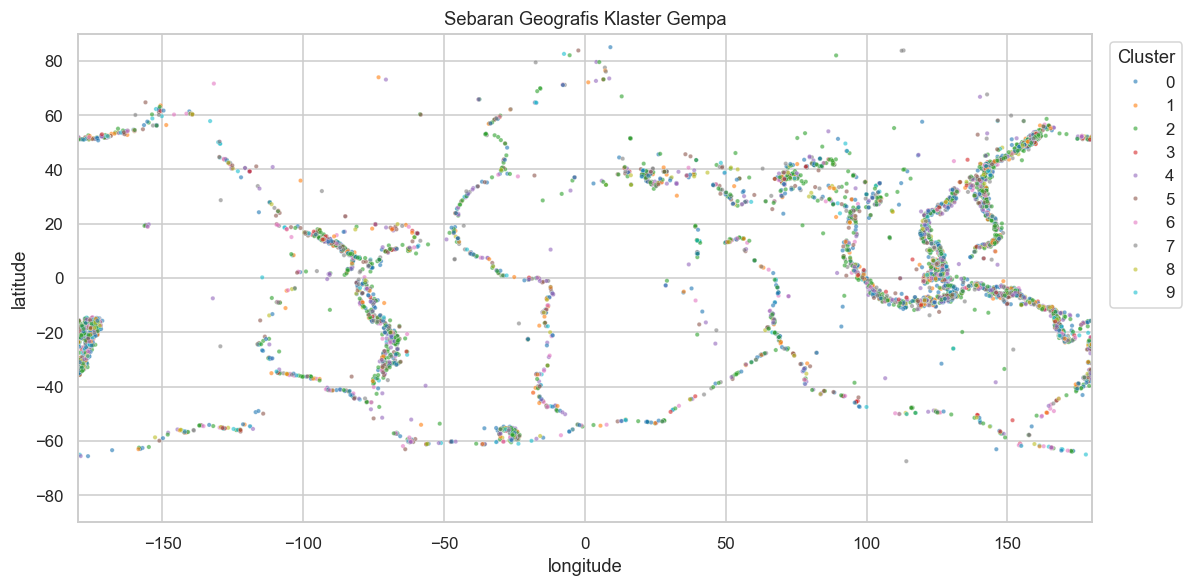

In [30]:
# Peta sebaran geografis klaster (jika ada latitude & longitude)
if {"latitude", "longitude"}.issubset(data.columns):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.scatterplot(data=tampil, x="longitude", y="latitude", hue="cluster", palette=palet, s=8, alpha=.6, ax=ax)
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
    ax.set_title("Sebaran Geografis Klaster Gempa"); ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.savefig("peta_cluster.png", bbox_inches="tight"); plt.show()

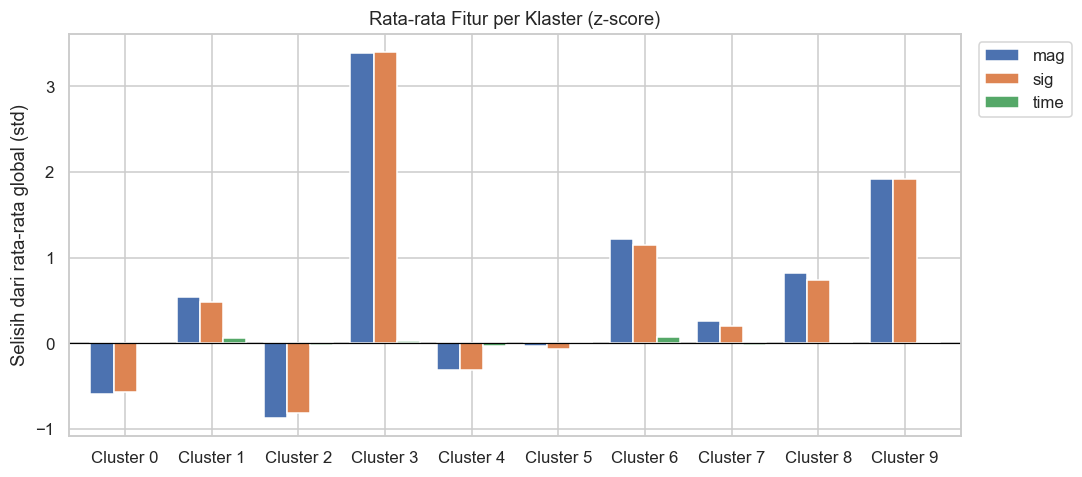

In [31]:
# Bar chart mean tiap fitur per klaster (fitur di-standarisasi agar sebanding)
pm = pd.DataFrame(z.values, index=[f"Cluster {c}" for c in z.index], columns=FITUR)
pm.plot(kind="bar", figsize=(10, 4.5), width=.8)
plt.axhline(0, color="black", lw=.8); plt.title("Rata-rata Fitur per Klaster (z-score)")
plt.ylabel("Selisih dari rata-rata global (std)"); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig("bar_profil_cluster.png", bbox_inches="tight"); plt.show()

In [32]:
data.to_csv(FILE_HASIL, index=False)
profil_mean.to_csv("ringkasan_cluster.csv")
hasil_k.to_csv("evaluasi_K.csv", index=False)
print("Tersimpan:", FILE_CSV, "|", FILE_HASIL, "| ringkasan_cluster.csv | evaluasi_K.csv")
print("Kolom 'cluster' sudah ditambahkan ->", "cluster" in data.columns)

Tersimpan: Chalista_Achira_Test3_ClusteringK-Means.csv | Chalista_Achira_Test3_ClusteringK-Means_hasil.csv | ringkasan_cluster.csv | evaluasi_K.csv
Kolom 'cluster' sudah ditambahkan -> True
